# Large Earth Observation Models in Action

## Monitoring land use change nationally

Spatial Data Science Conference · New York · October 20, 2026 · Noam Rosenthal, LGND

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EarthLegend/carto-sdsc-workshop-2026/blob/main/LGND_Geo_Agent_Demo.ipynb)

An embedding model turns an image chip (about 150 m across in NAIP) into a vector of a few hundred numbers. Chips that look alike get vectors that are close together. These are embeddings of imagery, not of tabular attributes about a place like the PlacePulse model in the CARTO session.

LGND has computed and indexed them for every chip in two archives: NAIP aerial imagery of the contiguous US (1 m, 2020–2024) and Sentinel-2 satellite imagery of all land (10 m, monthly since 2017). Finding every subdivision under construction in the country, or every field that became one, is a query against that index rather than an image processing job.

The index is served as MCP tools at `https://geo.lgnd.ai/mcp`. Any MCP client can use it, from directly calling tool calls to building custom agents. The [`lgnd-geo-sdk`](https://github.com/EarthLegend/lgnd-geo-sdk) package handles sign-in and the connection.

1. Connect
2. Scan the country for a feature and verify the matches against the imagery
3. Find where that change happened, when, and from what
4. Export to CARTO, your warehouse, or a desktop GIS
5. Hand the workflow to an LLM agent
6. An application: chat with a live map

**Before you start.** Sign up at the [LGND Geo developer portal](https://geo.lgnd.ai/portal), click **Create API key**, and write it down. An Anthropic API key will also be provided to you. The notebook will prompt you for these keys throughout the workshop.

In [ ]:
# Running in Colab? Install the packages and fetch this repo's helper files. Does nothing on a local run.
import sys

if "google.colab" in sys.modules:
    %pip install -q "lgnd-geo-sdk[pydantic-ai]==0.3.0" "pydantic-ai-slim[anthropic]" ipyleaflet "mistune>=3" pandas
    !rm -rf /content/workshop && git clone -q --depth 1 https://github.com/EarthLegend/carto-sdsc-workshop-2026 /content/workshop
    !cp -r /content/workshop/geo_show.py /content/workshop/geo_demo.py /content/workshop/assets /content/
    from google.colab import output
    output.enable_custom_widget_manager()

## 1. Connect

`client()` reads `LGND_GEO_API_KEY` from the environment and sends it with every request. `user_identity_get` returns who the key belongs to.

In [1]:
import os
from getpass import getpass

from lgnd_geo_sdk import client

if not os.environ.get("LGND_GEO_API_KEY"):
    os.environ["LGND_GEO_API_KEY"] = getpass("LGND Geo API key (https://geo.lgnd.ai/portal): ").strip()

async with client() as geo:
    me = await geo.call_tool("user_identity_get", {})

me.structured_content

LGND Geo API key (https://geo.lgnd.ai/portal):  ········


{'user_id': 'usr_01a0f8e605c0768282cfe693616dc84e',
 'email': 'jeff@lgnd.ai',
 'name': 'Jeff Albrecht',
 'internal': True}

The server lists its tools, including tool names, descriptions, and arguments.

In [2]:
import pandas as pd

async with client() as geo:
    tools = await geo.list_tools()

pd.DataFrame([{"tool": t.name, "description": t.description.split(". ")[0]} for t in tools]).set_index("tool")

,description
tool,
user_identity_get,Return the platform user these tools act for: ...
user_alias_set,"Give a node, change or classifier a short name..."
search_place_find,"Find places that look like something, in eithe..."
search_chip_lat_lon,"The newest chip at a point: its `chip_id`, its..."
search_change_find,Find places whose appearance changed from one ...
search_similar_change_find,Find observations or cells whose change looks ...
discover_area_view,Look at an area of one index at one level and ...
discover_area_shift_find,Rank an area's cells by how much they changed ...
discover_space_zoom,Move from a node through space


In [18]:
# One tool in full.
from geo_show import describe_tool

search = next(t for t in tools if t.name == "search_place_find")
describe_tool(search)

### `search_place_find`

Find places that look like something, in either index. Describe it in words with `text` (naip only), or give `like`: the id of an observation or cell that is the thing (the way to search s2). Returns up to `limit` matches, best first, each with its id, date or period, position and similarity. To label every place in an area instead, use toolbox_classifier_build and toolbox_classifier_apply.

For `text`, describe what an aerial photo of the thing shows, as a common noun: "solar farm", "hog farm", "charred forest". Avoid jargon, ground-level words ("wildfire") and words about time ("new"). Things smaller than about 10 m do not show on their own: describe their setting ("parking lot"). Try a few phrasings when it matters.

With `like`, level "observations" returns single images, one per place; a cell level returns cells in the node's own period. Takes a second or two.

| argument | | description |
|---|---|---|
| `index` | required | "naip" or "s2". |
| `text` |  | naip only: phrases for what an aerial photo shows, as common nouns ("solar farm"). Several are averaged. |
| `like` |  | The id (or name) of an observation or cell to resemble. |
| `area` |  | Where to look: a box {"south", "north", "west", "east"}, a circle {"lat", "lon", "radius_km"} or a polygon {"ring": [{"lat", "lon"}, ...]}, in degrees. Omit for the whole index. |
| `start` |  | Only observations on or after this date: YYYY, YYYY-MM or YYYY-MM-DD. |
| `end` |  | Only observations on or before this date: YYYY, YYYY-MM or YYYY-MM-DD. |
| `level` |  | With `like`: "observations" for single images, or a cell level number from the index's levels. Omit for the node's own kind. |
| `limit` |  | How many matches to return, 1-50. |

## 2. Scan the country for a feature

We'll start by calling a tool directly, no LLM required. Each row is one observation: a chip at a specific location for a specific date. `similarity` is the similarity between the embedding and the text query; calculated as cosine similarity.

In [20]:
async with client() as geo:
    result = await geo.call_tool(
        "search_place_find",
        {"index": "naip", "text": "housing subdivision under construction", "limit": 20},  # no area: the whole index
    )

found = result.structured_content
print({k: v for k, v in found.items() if k != "matches"})  # the query, as the server ran it

matches = pd.DataFrame(found["matches"]["rows"], columns=found["matches"]["columns"])
matches

{'index': 'naip', 'like': "'housing subdivision under construction'", 'at': 'observations', 'where': 'everywhere'}


,node,chip_id,place,observed,lat,lon,similarity
0,naip/obs:532118298,chip_39db7bdbfe604bb07bdebcbb771837f8,653fea9a23c2a1033a2b51f5cc857f2e,2021-11-04,34.8148,-87.6617,0.347
1,naip/obs:202392241,chip_be219c63c23d8b527f05e50e11570c0b,5b42845bb87789d642ed44b96f5e414f,2023-06-10,30.3261,-87.6590,0.341
2,naip/obs:17798560,chip_819ff44da377c8a001f7bb9b63cf4804,73e9380561ed3f62131760301a4787b3,2022-07-10,41.0110,-74.0137,0.340
3,naip/obs:437485334,chip_fbdfab853937243d72d9e3cebe9e0f7f,887a6c715a33cc528fedc88b5cd985a4,2021-11-26,34.7731,-86.9070,0.340
4,naip/obs:407200927,chip_5263548ffa96c1d8d04bc986bd7e54b1,9fed3e8c1ebecd2bf71c805edc2c77a4,2023-05-25,36.1314,-86.5145,0.339
5,naip/obs:298928004,chip_e0afb3da43516ed5badb839bff5e1698,14092383a56b50c308fda807af9cb4b9,2021-10-14,34.9125,-111.8239,0.338
6,naip/obs:352832420,chip_4981666057d8e1b5c41843f6d91c31de,eac55d8a722f1b988e43a6c9bcf521a6,2023-08-09,40.3657,-74.4587,0.338
7,naip/obs:556007291,chip_21c86af49957b931cffc1c7a650304f2,a02c56cd5f600facbcf92cd8c2d11e08,2023-07-14,42.9039,-112.4946,0.337
8,naip/obs:160685985,chip_09ed2e7ae061c5e02a67b9f9ab71375e,d01596a8f3a7ecdc44f506a7d716d966,2020-10-11,32.9894,-97.0472,0.337
9,naip/obs:120522116,chip_01ce9e344e0d4371a7f6cc4ef5be866f,8c8a69e212218f719ca13b01a7a0512c,2023-08-09,40.2866,-74.4788,0.337


In [21]:
from geo_show import show_map

show_map(found)

Map(center=[37.7735, -98.36285000000001], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_…

### Verify the matches against the imagery

A high score means the chip resembles the description, not that it is the thing: a subdivision under construction looks a lot like a cleared industrial site. The check fetches each chip's image and has an image model judge it against the claim. Nodes that pass are listed in `supported_at`; for the rest, it says what the image shows instead. Six nodes per call.

You can see the same images. The Geo API is a REST route beside the MCP server, `GET /api/v1/imagery?node=...`, with the same key; `thumbnails()` in `geo_show.py` calls it.

In [22]:
nodes = matches["node"].head(6).tolist()

async with client() as geo:
    result = await geo.call_tool(
        "reasoning_imagery_check",
        {
            "claim": "a residential subdivision under construction: graded lots, new streets, houses being built",
            "kind": "place",
            "nodes": nodes,
        },
    )

check = result.structured_content
check

{'verdict': 'supported',
 'supported_at': ['naip/obs:532118298',
  'naip/obs:202392241',
  'naip/obs:17798560',
  'naip/obs:437485334',
  'naip/obs:407200927',
  'naip/obs:298928004']}

In [23]:
verified = check.get("supported_at", [])
show_map(found, highlight=verified)  # green: verified

Map(center=[37.7735, -98.36285000000001], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_…


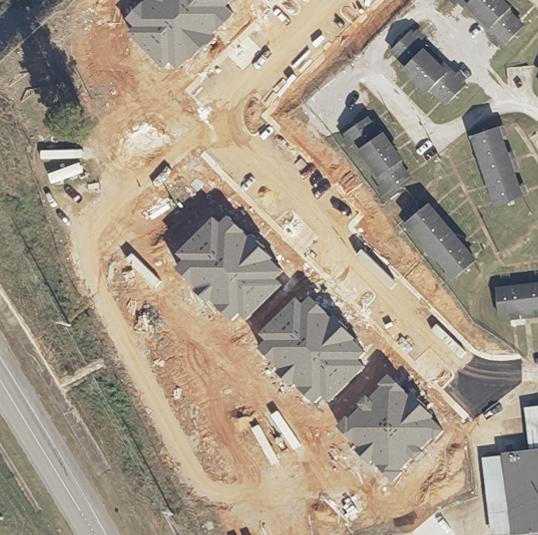
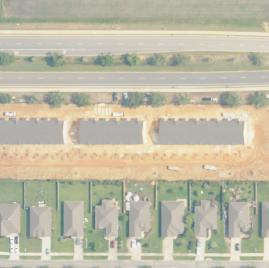
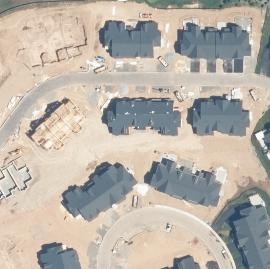
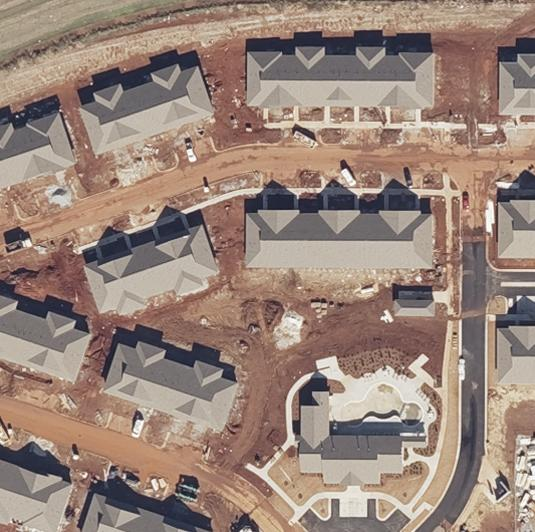
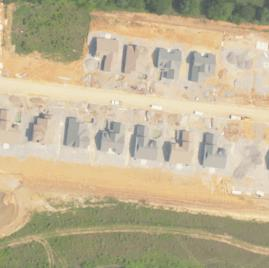
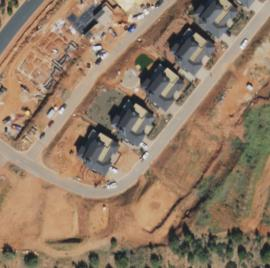

In [24]:
from geo_show import thumbnails

thumbnails(matches.head(6), verified)  # what the image model saw: green verified, red rejected

### Narrow the search

The same tool call but scoped to the Phoenix metro area, using imagery acquired after 2022.

In [27]:
PHOENIX = {"lat": 33.45, "lon": -112.07, "radius_km": 60}

async with client() as geo:
    result = await geo.call_tool(
        "search_place_find",
        {"index": "naip", "text": "housing subdivision under construction", "area": PHOENIX, "start": "2022", "limit": 10},
    )

nearby = result.structured_content
pd.DataFrame(nearby["matches"]["rows"], columns=nearby["matches"]["columns"])

,node,chip_id,place,observed,lat,lon,similarity
0,naip/obs:299123094,chip_b9efeca0b7f043bc68b121bccc01c809,0c5762b42fbb11ffbef5363ff9b11aae,2023-09-03,33.5155,-112.4779,0.324
1,naip/obs:406570287,chip_66beb84351f6d8cbbcd73189391392f6,d8c5cc4b597b495c28bd9d9e2474bb8a,2023-09-17,33.4724,-112.3805,0.322
2,naip/obs:489452997,chip_9284610d4d71f43fdf55ba7031cbcbcb,1a135f8c134b292519ece9afcce028d4,2023-09-15,33.3042,-111.8708,0.322
3,naip/obs:127550667,chip_dde2e485d765afc2bfe57d347bab6c26,e68d0dcfbeb8e6b0825055a065445544,2023-09-17,33.4925,-112.2811,0.320
4,naip/obs:178700333,chip_ad5b5f9964b985d2c63bf4523a542377,786f084def50f8416fd6143ea9e11aa8,2023-09-17,33.5874,-112.4354,0.320
5,naip/obs:272398303,chip_9d72c18873dd1aa8553f6111156b4668,4465b5a09d313f95b27210bdc7618d11,2023-09-17,33.4379,-112.2928,0.320
6,naip/obs:592658324,chip_db0c215c2e86f737af3768a2ce536fed,c3e419429fd16b2fe51ac9fcddd294c8,2023-09-17,33.3703,-112.0986,0.318
7,naip/obs:275247073,chip_fe4a692e0d3b5e55f468b00686636285,76b67f66b046cb09df2c690f9dbd0fb7,2023-09-15,33.2237,-111.6325,0.318
8,naip/obs:677228949,chip_277dfa17ad08a493e64baaa4c223cb27,1e2027b1bb1b90e2b9227a3847ff3bae,2023-09-17,33.4537,-112.3029,0.318
9,naip/obs:341578624,chip_78463ee9a77e0e8342e0342c94d98249,938de5003e1ed440c5b94f243d92ad27,2023-09-17,33.4911,-112.3375,0.317


In [28]:
show_map(nearby, area=PHOENIX)

Map(center=[33.405550000000005, -112.0552], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_i…

## 3. Change detection: where, when, from what

Section 2 found existing subdivisions during construction. This section finds places that became subdivisions. NAIP captured most of the country twice in between 2020 and 2024. The index encodes how each location changed across different time steps. Each result is one location with its before and after dates, identified as `naip/obs:12>obs:34`. This search covers the whole country.

In [29]:
async with client() as geo:
    result = await geo.call_tool(
        "search_change_find",
        {"index": "naip", "before": "farm fields", "after": "housing subdivision", "limit": 8},
    )

changes = result.structured_content
pairs = pd.DataFrame(changes["matches"]["rows"], columns=changes["matches"]["columns"])
pairs

,change,place,before,after,before_chip_id,after_chip_id,lat,lon,similarity
0,naip/obs:231391568>obs:89297225,2718dff8da67bf66f96e787996f2be13,2020-05-28,2022-05-24,chip_a4cf918d7c82faf8a377e70113599aa2,chip_64b880e0d3f7113ba8605dc5f7804d03,38.3534,-122.6825,0.432
1,naip/obs:217254188>obs:613245853,dda9e47804bf27a906b9a3e40a3e22c6,2021-06-29,2023-06-29,chip_b00f117e5ca24fbb8724f55a876c4e21,chip_942a816c3c690d66cc5a8282289cb937,46.2399,-119.9063,0.425
2,naip/obs:457872809>obs:40664917,c4378dea4a1bb416279e356c770a557f,2020-10-30,2022-09-13,chip_597c96a639fc049270f853bbd76cd390,chip_6399e9d337f5684aca21d29a1be0438d,29.8992,-95.7450,0.423
3,naip/obs:338570842>obs:53201138,3cb9d469d63dae2069241a2a08ed10d8,2020-05-28,2022-05-23,chip_48f1d30888cc11df9ca188324872e37a,chip_401f7c0e7acb6fc12482cfd22e597c3a,38.2916,-122.2737,0.422
4,naip/obs:626428469>obs:169954380,168d6ba87f3069708b47023b6ff28459,2020-10-30,2022-09-13,chip_072a4159c98a51a0175ca63f0e3b4355,chip_4f585b422ecdb7b682e00d821e802a15,29.8144,-95.8441,0.422
5,naip/obs:173447562>obs:21024918,fd9c4a70548f65e59036c12f53a1dfa8,2020-10-30,2022-09-13,chip_5dbcb5f5e59b8f220985c6f1a6e0534f,chip_529f24898d92b03c89504e6827a0d856,29.9036,-95.7374,0.421
6,naip/obs:560632563>obs:363060593,af110c4ec1dc1e3fdd1c56185a4ae57e,2020-06-11,2022-07-09,chip_2f77c16037f375d66066292f0d83b55b,chip_23adc8b11ee66d1baee3c4cc7aa501a2,30.5432,-96.6743,0.421
7,naip/obs:514706652>obs:404271002,0585c77663cf73ccebb80a9681099bfa,2021-06-17,2023-07-12,chip_8aae24b630a8481ecaaa49741f1a23e3,chip_b7e608cb025ec75802bbcb02c5c2e1a7,39.0850,-77.2528,0.420


In [30]:
show_map(changes)

Map(center=[38.02715, -99.96764999999999], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in…

### When did it change

Every observation of the location in date order, with each one's similarity to the previous one. On NAIP that is two or three observations, enough to place the change between two dates; on Sentinel-2, with a monthly record, within a month.

In [31]:
top = pairs.iloc[0]
before_node = top["change"].split(">")[0]  # the observation before the change

async with client() as geo:
    result = await geo.call_tool("discover_time_zoom", {"node": before_node})

series = result.structured_content
print(f"{series['steps']} observations, {series['span'][0]} → {series['span'][1]}")
pd.DataFrame(series["rows"], columns=series["columns"])

2 observations, 2020-05-28 → 2022-05-24


,observed,node,to_previous,to_first_clear
0,2020-05-28,naip/obs:231391568,NaN,1.00
1,2022-05-24,naip/obs:89297225,0.76,0.76


### What changed

The two images of the change, then the same check on the change node: the image model sees before and after and judges whether they show the change described. This separates a land use change from a seasonal difference or a new crop.


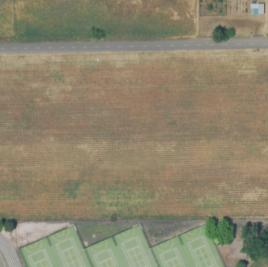
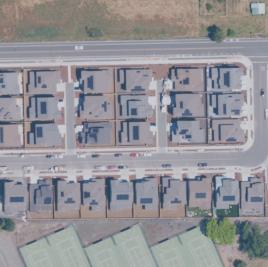

In [33]:
from geo_show import before_after

before_after(top)

In [34]:
print(f"{top['change']}   {top['before']} → {top['after']}   at {top['lat']}, {top['lon']}")

async with client() as geo:
    result = await geo.call_tool(
        "reasoning_imagery_check",
        {
            "claim": "open farm fields were replaced by a housing subdivision with streets and houses",
            "kind": "change",
            "nodes": [top["change"]],
        },
    )

result.structured_content

naip/obs:231391568>obs:89297225   2020-05-28 → 2022-05-24   at 38.3534, -122.6825


{'verdict': 'supported', 'supported_at': ['naip/obs:231391568>obs:89297225']}

## 4. Export to CARTO, your warehouse, or a desktop GIS

GeoJSON for the verified subdivisions, CSV with lat/lon for the change pairs. Both import into CARTO; the CSV loads into a BigQuery, Snowflake or Databricks table; both open in QGIS or ArcGIS. The node id on each record is the way back to the imagery and the input to any further tool call.

In [35]:
import json

features = [
    {
        "type": "Feature",
        "geometry": {"type": "Point", "coordinates": [row["lon"], row["lat"]]},
        "properties": {
            "node": row["node"],
            "observed": row["observed"],
            "similarity": row["similarity"],
            "verified": row["node"] in verified,
        },
    }
    for row in matches.to_dict("records")
]
with open("subdivisions_under_construction.geojson", "w") as f:
    json.dump({"type": "FeatureCollection", "features": features}, f)

# lat/lon columns: imports into CARTO as points, loads into a warehouse table as is
pairs.to_csv("farmland_to_housing.csv", index=False)

print(f"subdivisions_under_construction.geojson: {len(features)} points, {len(verified)} verified")
print(f"farmland_to_housing.csv: {len(pairs)} change pairs")

subdivisions_under_construction.geojson: 20 points, 6 verified
farmland_to_housing.csv: 8 change pairs


## 5. Hand the workflow to an LLM

Sections 2 through 4 show ho a user can manually certain tools while passing data in between tool calls. Next we'll show how to plug the same tool calls into an LLM through the [`lgnd-geo-sdk`](https://github.com/EarthLegend/lgnd-geo-sdk) which makes it easy to build your own chat loops and agents through [Pydantic AI](https://pydantic.dev/docs/ai/). Pydantic allows integrating LGND tool calls with a number of LLMs such as Anthropic, OpenAI, Gemini, AWS Bedrock, and many more. Each cell prints out the reasoning trace as it runs.

In [3]:
from pydantic_ai import Agent
from pydantic_ai.models.anthropic import AnthropicModelSettings

from geo_show import stream
from lgnd_geo_sdk.pydantic_ai import toolset

if not os.environ.get("ANTHROPIC_API_KEY"):
    os.environ["ANTHROPIC_API_KEY"] = getpass("Anthropic API key: ").strip()

# Return summarized thinking so it can be streamed.
THINKING = AnthropicModelSettings(anthropic_thinking={"type": "adaptive", "display": "summarized"})

agent = Agent("anthropic:claude-opus-5-5", toolsets=[toolset()], model_settings=THINKING)
run = await stream(agent, "Where in the US has farmland been converted to housing? Verify the five strongest cases against the imagery and give me their dates.")

HTML(value='')

### Build a customer user persona

Instructions allow you to tailor the system prompt used by the LLM. This provides an additional level of customization for tailoring your agent to a specific user persona or task.

In [37]:
INSTRUCTIONS = """\
I'm a planner tracking residential development across the US. Search the naip index. Leave the
area open unless I name a region.

Verify every finding with reasoning_imagery_check before reporting it. Report only the locations
it supported, and say how many it rejected and what they showed instead. Keep answers short: a
table of findings with the nearest town, the dates and coordinates, then a line of caveats."""

planner = Agent("anthropic:claude-opus-5-5", toolsets=[toolset()], instructions=INSTRUCTIONS, model_settings=THINKING)

run = await stream(planner, "Where around Phoenix has farmland become housing since 2021?")

HTML(value='')

In [ ]:
# A follow-up, in the same conversation.
run = await stream(planner, "Which of those are built out, and which are still under construction?", message_history=run.all_messages())

## 6. An application

Pulling this all together, this last example shows an application built entirely on top of `lgnd-geo-sdk`. The backend runs an agent tasked with answering a question about the Earth and reporting back verifiable findings. The frontend follows the agent's thinking in real time on the map. Each finding becomes a numbered pin, green where the imagery supported the claim and red where it didn't. The final answer provided by the application cites these findings to create a report that answers the user's original question.

This example utilizes both NAIP and Sentinel2 embeddings in the same prompt.

In [ ]:
from geo_demo import GeoChat

APP_INSTRUCTIONS = """\
You are an Earth analyst. You answer questions about places on Earth, what is there, what changed
and when, from the imagery indexes: naip for the contiguous US, s2 for the rest of the world and
for dating a change by month.

Verify every finding with reasoning_imagery_check before reporting it. A map next to the chat
shows the area and results of each tool call, and each imagery check becomes a numbered finding
on it; the check's result carries `finding`, the number. Cite findings in your answer as [1], [2].
Name places rather than ids or coordinates, and do not mention embeddings, similarity scores,
node ids or tool names in your visible reasoning or your answer. Lead with the answer in a
sentence or two, then the evidence."""

# The earth agent's example questions, verbatim.
DEMO = [
    "Where around Phoenix has new housing gone up since 2020?",
    "Walk me through the build out of fracking pads in the Permian Basin after 2020.",
    "Which parts of California's Central Valley look like they converted orchards to solar farms?",
    "Which low income neighborhoods in LA have seen investment into public transportation?",
    "Describe key energy infrastructure changes along the coasts of the persian gulf since 2020.",
    "Show me parts of China have seen significant investment for high speed train lines in the last five years.",
    "Summarize how mining has changed Kiruna, Sweden over the past 10 years.",
    "Show me burn scar of recent European wildfires and how the areas have recovered since.",
]

app = GeoChat(
    Agent("anthropic:claude-opus-5-5", toolsets=[toolset()], instructions=APP_INSTRUCTIONS, model_settings=THINKING),
    examples=DEMO,
)
app

## Where to go from here

- **Other agent frameworks.** The server is standard MCP over HTTP with OAuth. `client()` and `auth()` work with any MCP client; LangGraph, the OpenAI Agents SDK or your own loop connect the same way. Pydantic AI is the adapter the SDK ships; for another, [open an issue](https://github.com/EarthLegend/lgnd-geo-sdk/issues).
- **No code.** Claude Code: `claude plugin marketplace add EarthLegend/skills`, then `claude plugin install lgnd-geo@lgnd`. Claude.ai, Claude Desktop or Cursor: add `https://geo.lgnd.ai/mcp` as an MCP server. The plugin's skills cover exhaustive search over an area with a classifier.
- **Your own area.** Sections 2 to 4 are a description, an area and a date range. Change those.
- **Docs and source:** [earthlegend.github.io/lgnd-geo-sdk](https://earthlegend.github.io/lgnd-geo-sdk/) · [github.com/EarthLegend/lgnd-geo-sdk](https://github.com/EarthLegend/lgnd-geo-sdk)